# Credit Card Fraud Detection

## Project Overview

This project uses machine learning to identify potentially fraudulent credit card transactions. The main challenge is that fraudulent transactions make up a very small part of the dataset, so accuracy by itself does not tell us whether a model is doing a good job.

I explored the data, prepare it for modelling, compare different ways of handling class imbalance, and evaluate several classification models. I use precision, recall, F1-score and PR-AUC to understand how well each model identifies fraud.

The aim is to compare the models fairly and understand the trade-off between catching fraudulent transactions and incorrectly flagging genuine ones.

## 1. Import Libraries

The libraries below are used for data handling, visualisation, preprocessing and model building. I have kept the imports together so the notebook is easier to run from the beginning.

### Environment Setup

The notebook uses `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `imbalanced-learn` and `xgboost`. If any of these packages are missing from your environment, install them before running the notebook:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost
```

In [7]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    average_precision_score, precision_recall_curve,
    make_scorer
)

RANDOM_STATE = 42

## 2. Load the Dataset

Place `creditcard.csv` in the same folder as this notebook before running the cell. This relative path makes the notebook easier to run on another computer than a path tied to one person's Downloads folder.

In [8]:
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Understand the Dataset

The dataset contains transaction details and a target column named `Class`. A value of `0` represents a genuine transaction, while `1` represents a fraudulent transaction.

The `V1` to `V28` columns are transformed features. Their original meaning is not available in the dataset, so the analysis focuses on their distributions and relationship with the target rather than assigning them business meanings.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [11]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset shape: (284807, 31)

Missing values:
0


## 4. Check and Remove Duplicate Rows

I first check how many exact duplicate rows are present and how they are distributed across the two classes. Exact duplicates are removed before modelling so the same transaction record is not counted more than once.

In [12]:
duplicate_rows = df[df.duplicated(keep=False)]
print("Number of duplicate rows:", df.duplicated().sum())

if not duplicate_rows.empty:
    print("\nClass distribution among rows involved in duplicates:")
    print(duplicate_rows["Class"].value_counts())

df = df.drop_duplicates(keep="first").copy()
print("\nShape after removing duplicates:", df.shape)

Number of duplicate rows: 1081

Class distribution among rows involved in duplicates:
Class
0    1822
1      32
Name: count, dtype: int64

Shape after removing duplicates: (283726, 31)


## 5. Exploratory Data Analysis

### Class distribution

Fraud cases are much less common than genuine transactions. This imbalance matters: a model that predicts every transaction as genuine could still achieve very high accuracy while missing all fraud cases.

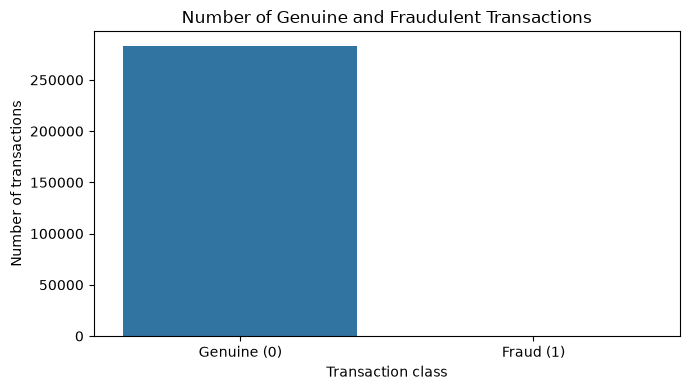

Class percentages:
Class
0    99.833
1     0.167
Name: proportion, dtype: float64


In [13]:
class_counts = df["Class"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="Class")
ax.set_xticklabels(["Genuine (0)", "Fraud (1)"])
plt.title("Number of Genuine and Fraudulent Transactions")
plt.xlabel("Transaction class")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

print("Class percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(3))

Because the dataset is imbalanced, I will not use accuracy as the only measure. Precision tells us how many transactions flagged as fraud were actually fraud. Recall tells us how much of the actual fraud was detected. F1-score balances precision and recall, while PR-AUC summarises the precision-recall trade-off across thresholds.

### Transaction time and amount

The original dataset provides `Time` as seconds elapsed since the first transaction in the dataset and `Amount` as the transaction amount. These are two of the few features whose meaning is directly available.

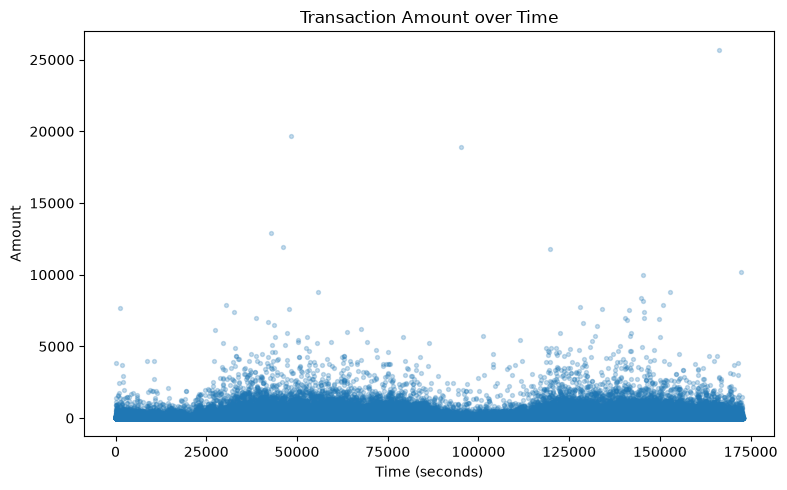

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Time"], df["Amount"], alpha=0.25, s=8)
plt.title("Transaction Amount over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()

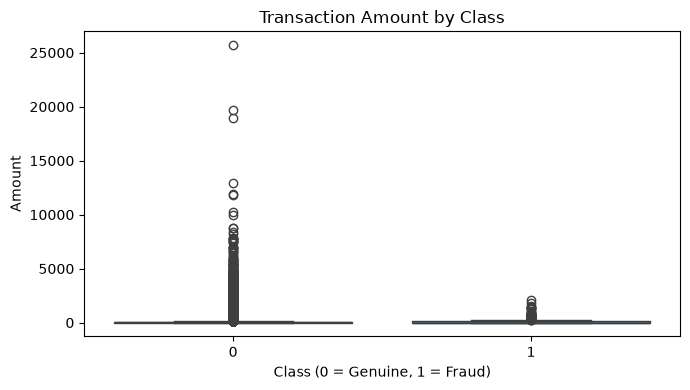

In [15]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Class", y="Amount")
plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()

The amount distribution is strongly skewed, with a small number of large transactions. The boxplot also helps compare the spread of amounts in the two classes. A boxplot can hide many points when the distribution is highly skewed, so I treat it as a broad comparison rather than a complete picture of every transaction.

### Add an hour feature

I create an `Hour` feature from `Time` to look at the approximate hour within a 24-hour cycle. This is a simple transformation of an existing feature; it does not use the target column.

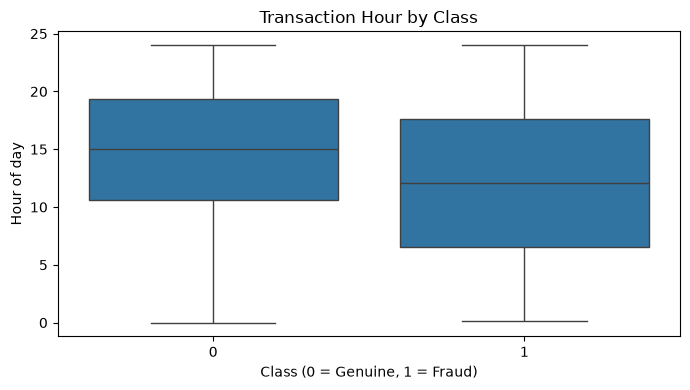

In [16]:
df["Hour"] = (df["Time"] / 3600) % 24

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Class", y="Hour")
plt.title("Transaction Hour by Class")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Hour of day")
plt.tight_layout()
plt.show()

The distributions overlap considerably, so the hour alone does not clearly separate fraudulent and genuine transactions. It can still be retained as one of the input features for the models.

### Look at the transformed `V` features

The `V1` to `V28` columns are anonymised. I compare their distributions across the two classes to see which features show visible differences.

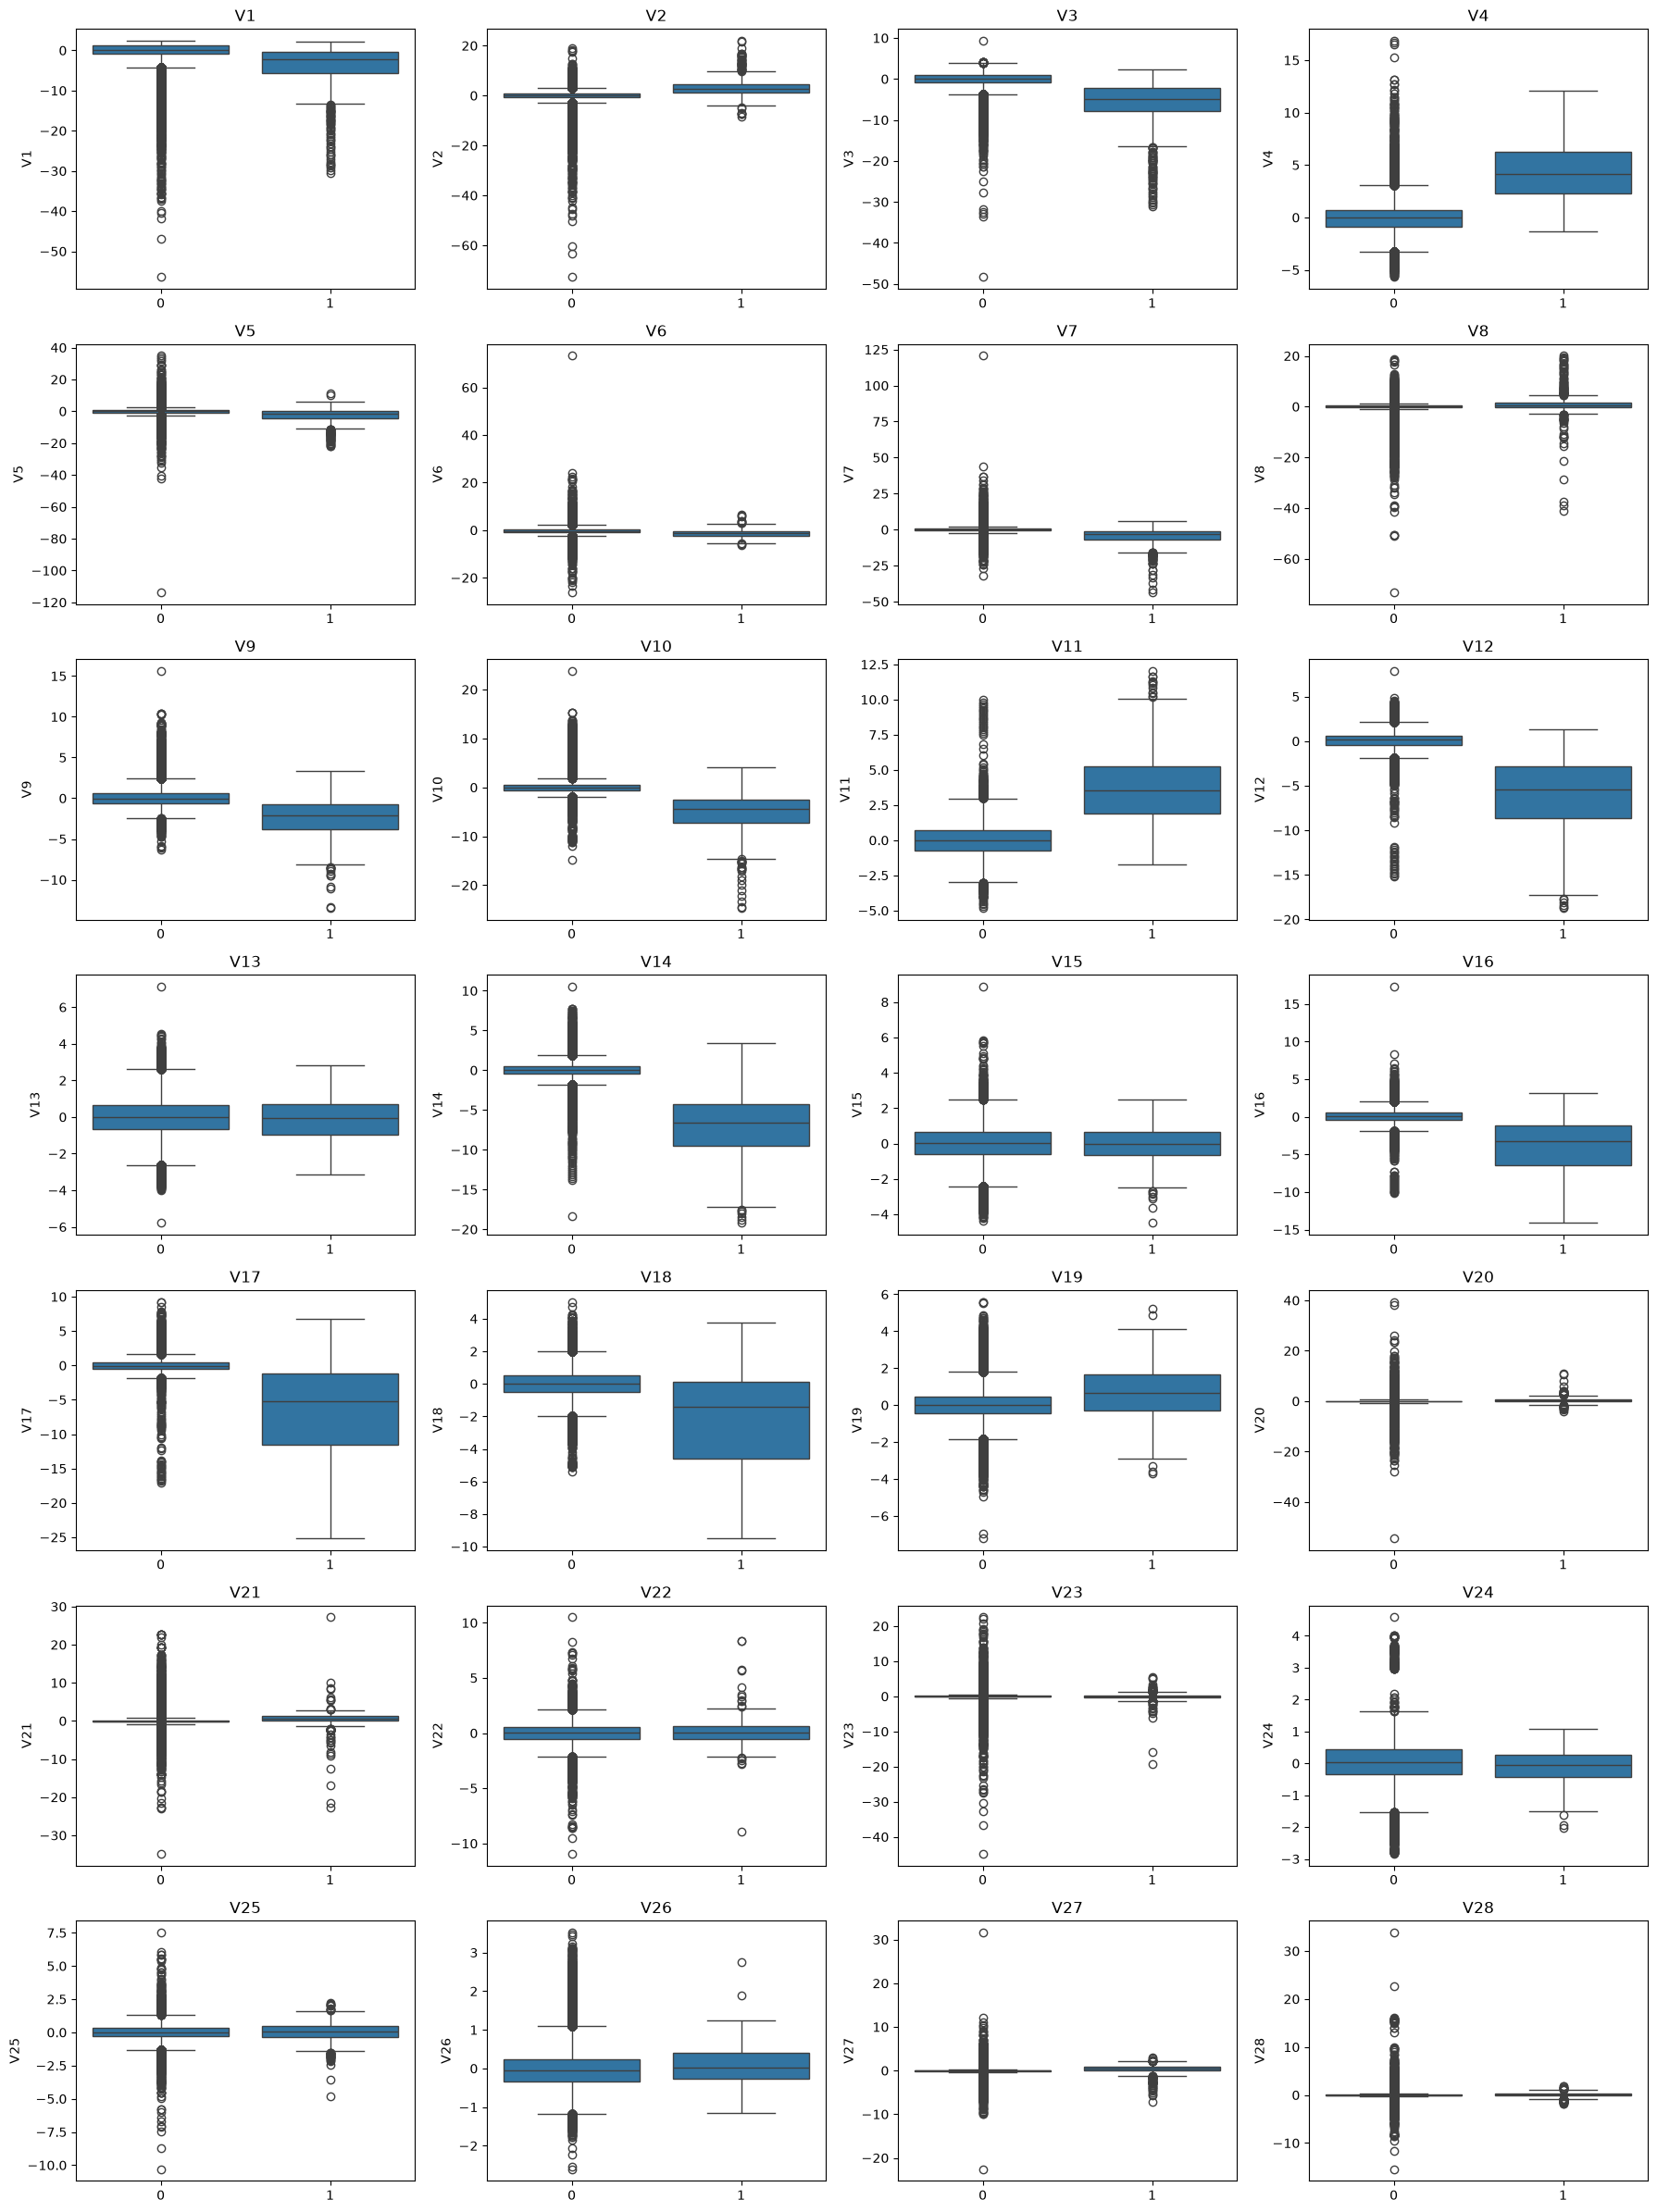

In [17]:
v_features = [f"V{i}" for i in range(1, 29)]

fig, axes = plt.subplots(7, 4, figsize=(18, 24))
for feature, ax in zip(v_features, axes.flat):
    sns.boxplot(data=df, x="Class", y=feature, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [18]:
class_correlations = df.corr(numeric_only=True)["Class"].drop("Class")
top_correlations = class_correlations.abs().sort_values(ascending=False).head(10)
print(top_correlations)

V17    0.313498
V14    0.293375
V12    0.250711
V10    0.206971
V16    0.187186
V3     0.182322
V7     0.172347
V11    0.149067
V4     0.129326
V18    0.105340
Name: Class, dtype: float64


The correlation values show which individual features have the strongest linear relationship with the target. In this dataset, several of the `V` features stand out. Correlation is only a first check, though; it does not capture every pattern a machine learning model may learn.

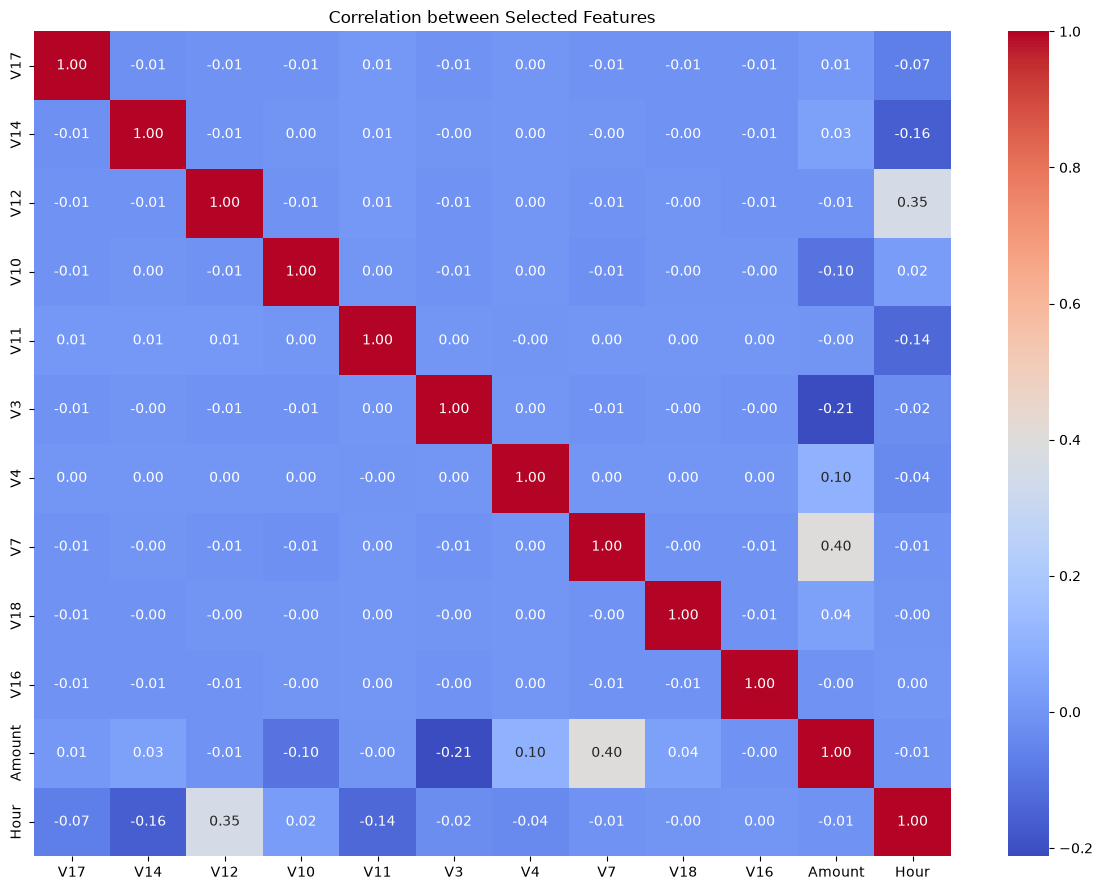

In [19]:
heatmap_features = [
    "V17", "V14", "V12", "V10", "V11", "V3",
    "V4", "V7", "V18", "V16", "Amount", "Hour"
]

plt.figure(figsize=(12, 9))
sns.heatmap(df[heatmap_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between Selected Features")
plt.tight_layout()
plt.show()

### Check outliers in transaction amount

I use the IQR rule to identify unusually low or high transaction amounts. These points are not automatically errors. In fraud detection, removing unusual transactions without checking them could also remove useful fraud examples.

In [20]:
q1 = df["Amount"].quantile(0.25)
q3 = df["Amount"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df["Amount"] < lower_bound) | (df["Amount"] > upper_bound)]
fraud_outliers = outliers[outliers["Class"] == 1]

print("Total amount outliers:", len(outliers))
print("Fraud cases among these outliers:", len(fraud_outliers))

Total amount outliers: 31685
Fraud cases among these outliers: 87


I keep these rows. The IQR rule only tells us that an amount is far from the middle of the distribution; it does not mean the transaction is invalid. Removing them could discard genuine examples and potentially useful fraud patterns.

## 6. Prepare the Data

I use an 80:20 train-test split and stratify by `Class`. Stratification keeps the proportion of fraud cases similar in both sets. The test set is held back for the final comparison and is not used to fit preprocessing steps or train models.

I keep the original features, including `Time`, `Amount` and the derived `Hour`. The scaling of `Amount`, `Time` and `Hour` is moved into a pipeline for the Logistic Regression experiments. This is important because the scaler must be fitted separately inside each cross-validation training fold.

In [21]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nFraud percentage in training set:", round(y_train.mean() * 100, 3), "%")
print("Fraud percentage in test set:", round(y_test.mean() * 100, 3), "%")

Training set: (226980, 31)
Test set: (56746, 31)

Fraud percentage in training set: 0.167 %
Fraud percentage in test set: 0.167 %


## 7. Preprocessing for Logistic Regression

Logistic Regression can be affected by differences in feature scales. I use `RobustScaler` for `Amount`, `Time` and `Hour`, since it uses the median and interquartile range and is less affected by extreme values.

The preprocessing is placed inside a `ColumnTransformer` and pipeline. That way, during cross-validation, the scaler is fitted only on the training fold. The tree-based models do not require this scaling, so they use the original feature values.

In [22]:
scaled_columns = ["Amount", "Time", "Hour"]

preprocessor = ColumnTransformer(
    transformers=[("robust_scaler", RobustScaler(), scaled_columns)],
    remainder="passthrough"
)

def make_logistic_pipeline(class_weight=None):
    return SklearnPipeline([
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight=class_weight
        ))
    ])

## 8. Evaluation Function

I use the same set of test metrics for every model. In addition to precision, recall, F1-score and PR-AUC, I include false positives (genuine transactions flagged as fraud) and false negatives (fraudulent transactions missed by the model).

In [23]:
results = []

def evaluate_model(name, y_true, y_pred, probabilities):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "Model": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "False Positives": fp,
        "False Negatives": fn
    }

def evaluate_and_store(name, model, X_eval=X_test, y_eval=y_test):
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]

    results.append(
        evaluate_model(name, y_eval, predictions, probabilities)
    )

    print(f"Results for {name}")
    print(classification_report(y_eval, predictions, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_eval, predictions))
    print("PR-AUC:", round(average_precision_score(y_eval, probabilities), 4))

    return predictions, probabilities

## 9. Logistic Regression: Baseline

I start with Logistic Regression without any class-imbalance adjustment. This gives us a baseline to compare against the later experiments.

In [24]:
lr_baseline = make_logistic_pipeline()
lr_baseline.fit(X_train, y_train)

lr_base_pred, lr_base_prob = evaluate_and_store(
    "Logistic Regression (Baseline)", lr_baseline
)

Results for Logistic Regression (Baseline)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.59      0.70        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.85     56746
weighted avg       1.00      1.00      1.00     56746

Confusion matrix:
[[56641    10]
 [   39    56]]
PR-AUC: 0.6928


## 10. Logistic Regression with Class Weighting

The `balanced` class-weight option gives more weight to the minority class during training. This can help the model pay more attention to fraud, although it may also increase the number of genuine transactions incorrectly flagged as fraud.

In [25]:
lr_balanced = make_logistic_pipeline(class_weight="balanced")
lr_balanced.fit(X_train, y_train)

lr_bal_pred, lr_bal_prob = evaluate_and_store(
    "Logistic Regression (Class Weighting)", lr_balanced
)

Results for Logistic Regression (Class Weighting)
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.06      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.97      0.99     56746

Confusion matrix:
[[55234  1417]
 [   12    83]]
PR-AUC: 0.6737


## 11. Logistic Regression with SMOTE

SMOTE creates synthetic examples of the minority class using examples from the training data. I apply it only to the training data. The test set keeps its original class distribution so the final evaluation reflects the original problem.

SMOTE is included inside the pipeline so it is applied separately within each training fold during cross-validation.

In [26]:
lr_smote = ImbPipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000))
])

lr_smote.fit(X_train, y_train)

lr_smote_pred, lr_smote_prob = evaluate_and_store(
    "Logistic Regression (SMOTE)", lr_smote
)

Results for Logistic Regression (SMOTE)
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.98     56746

Confusion matrix:
[[55139  1512]
 [   12    83]]
PR-AUC: 0.6786


The class-weighting and SMOTE experiments are useful comparisons, even if they do not produce the best balance of precision and recall. In a highly imbalanced problem, increasing recall can also lead to many more false positives. The right balance depends on how costly missed fraud and unnecessary transaction reviews are.

## 12. Cross-Validation for the Initial Models

I use 5-fold Stratified Cross-Validation on the training set for the Logistic Regression variants and the selected Decision Tree. Stratification keeps fraud represented in each fold.

The preprocessing and SMOTE steps are inside their respective pipelines, so they are fitted only on each fold's training portion. I do not repeat this cross-validation for the more time-consuming ensemble models in this final notebook. Their selected configurations are trained once and compared on the same held-out test set.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def false_negative_count(y_true, y_pred):
    return confusion_matrix(y_true, y_pred, labels=[0, 1])[1, 0]

def false_positive_count(y_true, y_pred):
    return confusion_matrix(y_true, y_pred, labels=[0, 1])[0, 1]

cv_scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "pr_auc": "average_precision",
    "fn": make_scorer(false_negative_count),
    "fp": make_scorer(false_positive_count)
}

def cross_validate_model(model, name):
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=cv_scoring,
        n_jobs=-1,
        return_train_score=False
    )

    return {
        "Model": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "PR-AUC (CV)": scores["test_pr_auc"].mean(),
        "PR-AUC Std": scores["test_pr_auc"].std(),
        "FN per fold": scores["test_fn"].mean(),
        "FP per fold": scores["test_fp"].mean()
    }

cv_models = [
    (make_logistic_pipeline(), "Logistic Regression (Baseline)"),
    (make_logistic_pipeline(class_weight="balanced"), "Logistic Regression (Class Weighting)"),
    (lr_smote, "Logistic Regression (SMOTE)")
]

cv_results = [
    cross_validate_model(model, name)
    for model, name in cv_models
]

cv_results_df = pd.DataFrame(cv_results)
cv_results_df.round(3)

,Model,Precision,Recall,F1 Score,PR-AUC (CV),PR-AUC Std,FN per fold,FP per fold
0,Logistic Regression (Baseline),0.866,0.606,0.711,0.756,0.030,29.8,7.2
1,Logistic Regression (Class Weighting),0.060,0.915,0.112,0.754,0.027,6.4,1102.0
2,Logistic Regression (SMOTE),0.056,0.907,0.106,0.753,0.027,7.0,1160.6


## 13. Decision Tree Classifier

The earlier experiments compared different tree depths. A maximum depth of 5 was selected as a practical balance between model complexity and validation performance. I use that selected depth directly here rather than repeating the depth search every time the notebook is run.

In [28]:
decision_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=RANDOM_STATE
)

dt_cv_result = cross_validate_model(
    decision_tree,
    "Decision Tree (max_depth=5)"
)

pd.DataFrame([dt_cv_result]).round(3)

,Model,Precision,Recall,F1 Score,PR-AUC (CV),PR-AUC Std,FN per fold,FP per fold
0,Decision Tree (max_depth=5),0.898,0.778,0.833,0.743,0.042,16.8,6.8


In [29]:
decision_tree.fit(X_train, y_train)

dt_pred, dt_prob = evaluate_and_store(
    "Decision Tree", decision_tree
)

Results for Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.89      0.71      0.79        95

    accuracy                           1.00     56746
   macro avg       0.95      0.85      0.89     56746
weighted avg       1.00      1.00      1.00     56746

Confusion matrix:
[[56643     8]
 [   28    67]]
PR-AUC: 0.657


## 14. Random Forest Classifier

The Random Forest configuration below was selected in the earlier parameter search. I use those recorded values directly instead of running GridSearchCV again. This saves the time which was to be used for testing different parameter combinations.
The earlier search selected 200 trees, a maximum depth of 10 and no class weighting.

In [30]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight=None,
    random_state=20,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

rf_pred, rf_prob = evaluate_and_store(
    "Random Forest", random_forest
)

Results for Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.72      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Confusion matrix:
[[56649     2]
 [   27    68]]
PR-AUC: 0.7895


## 15. AdaBoost Classifier

The AdaBoost parameters below are also taken from the earlier search: 200 estimators and a learning rate of 1.0. The model is trained once on the training set.

In [31]:
adaboost = AdaBoostClassifier(
    n_estimators=200,
    learning_rate=1.0,
    random_state=42
)

adaboost.fit(X_train, y_train)

ada_pred, ada_prob = evaluate_and_store(
    "AdaBoost", adaboost
)

Results for AdaBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.84      0.69      0.76        95

    accuracy                           1.00     56746
   macro avg       0.92      0.85      0.88     56746
weighted avg       1.00      1.00      1.00     56746

Confusion matrix:
[[56638    13]
 [   29    66]]
PR-AUC: 0.6683


## 16. XGBoost Classifier

The earlier parameter search selected 200 estimators, a maximum depth of 5 and a learning rate of 0.05. I keep those settings and train XGBoost directly, without repeating the search.

In [32]:
xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=20,
    eval_metric="logloss",
    n_jobs=-1
)

xgboost_model.fit(X_train, y_train)

xgb_pred, xgb_prob = evaluate_and_store(
    "XGBoost", xgboost_model
)

Results for XGBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.74      0.83        95

    accuracy                           1.00     56746
   macro avg       0.98      0.87      0.92     56746
weighted avg       1.00      1.00      1.00     56746

Confusion matrix:
[[56648     3]
 [   25    70]]
PR-AUC: 0.8188


## 17. Compare the Models on the Test Set

All models below are evaluated on the same untouched test set. The results are rounded for readability. The test set contains the original class distribution, so the metrics are more informative than accuracy alone.

In [33]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("PR-AUC", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,Precision,Recall,F1 Score,PR-AUC,False Positives,False Negatives
0,XGBoost,0.959,0.737,0.833,0.819,3,25
1,Random Forest,0.971,0.716,0.824,0.790,2,27
2,Logistic Regression (Baseline),0.848,0.589,0.696,0.693,10,39
3,Logistic Regression (SMOTE),0.052,0.874,0.098,0.679,1512,12
4,Logistic Regression (Class Weighting),0.055,0.874,0.104,0.674,1417,12
5,AdaBoost,0.835,0.695,0.759,0.668,13,29
6,Decision Tree,0.893,0.705,0.788,0.657,8,28


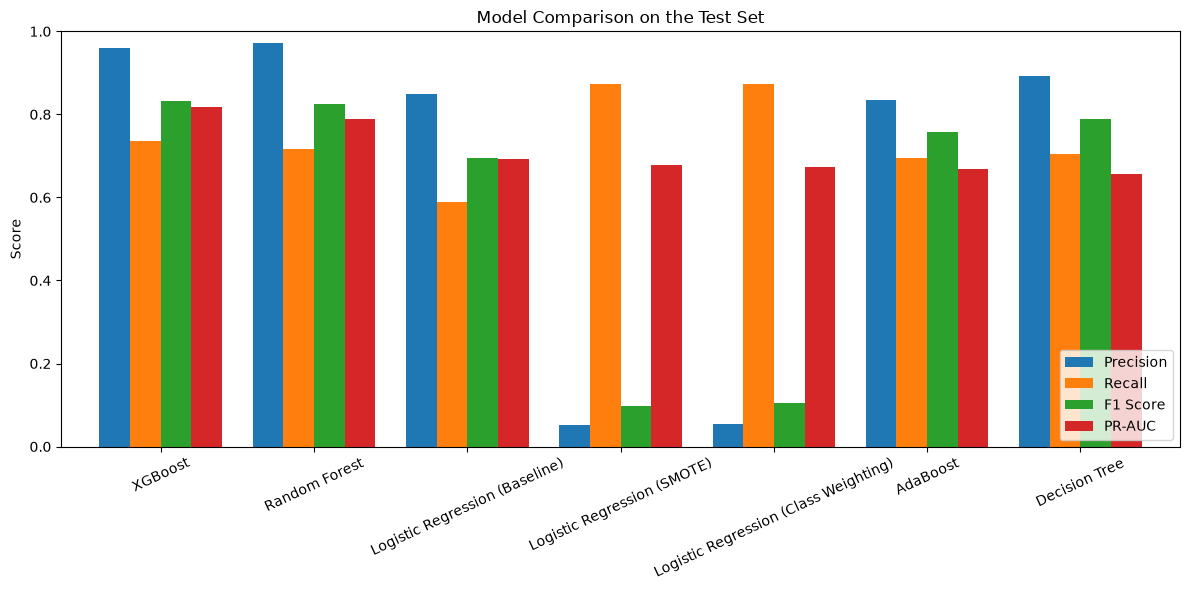

In [34]:
comparison_metrics = ["Precision", "Recall", "F1 Score", "PR-AUC"]

ax = results_df.set_index("Model")[comparison_metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)
ax.set_title("Model Comparison on the Test Set")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 18. Confusion Matrices

A confusion matrix makes the types of errors easier to understand. The top-left and bottom-right cells show correct predictions, while the other two cells show false positives and false negatives.

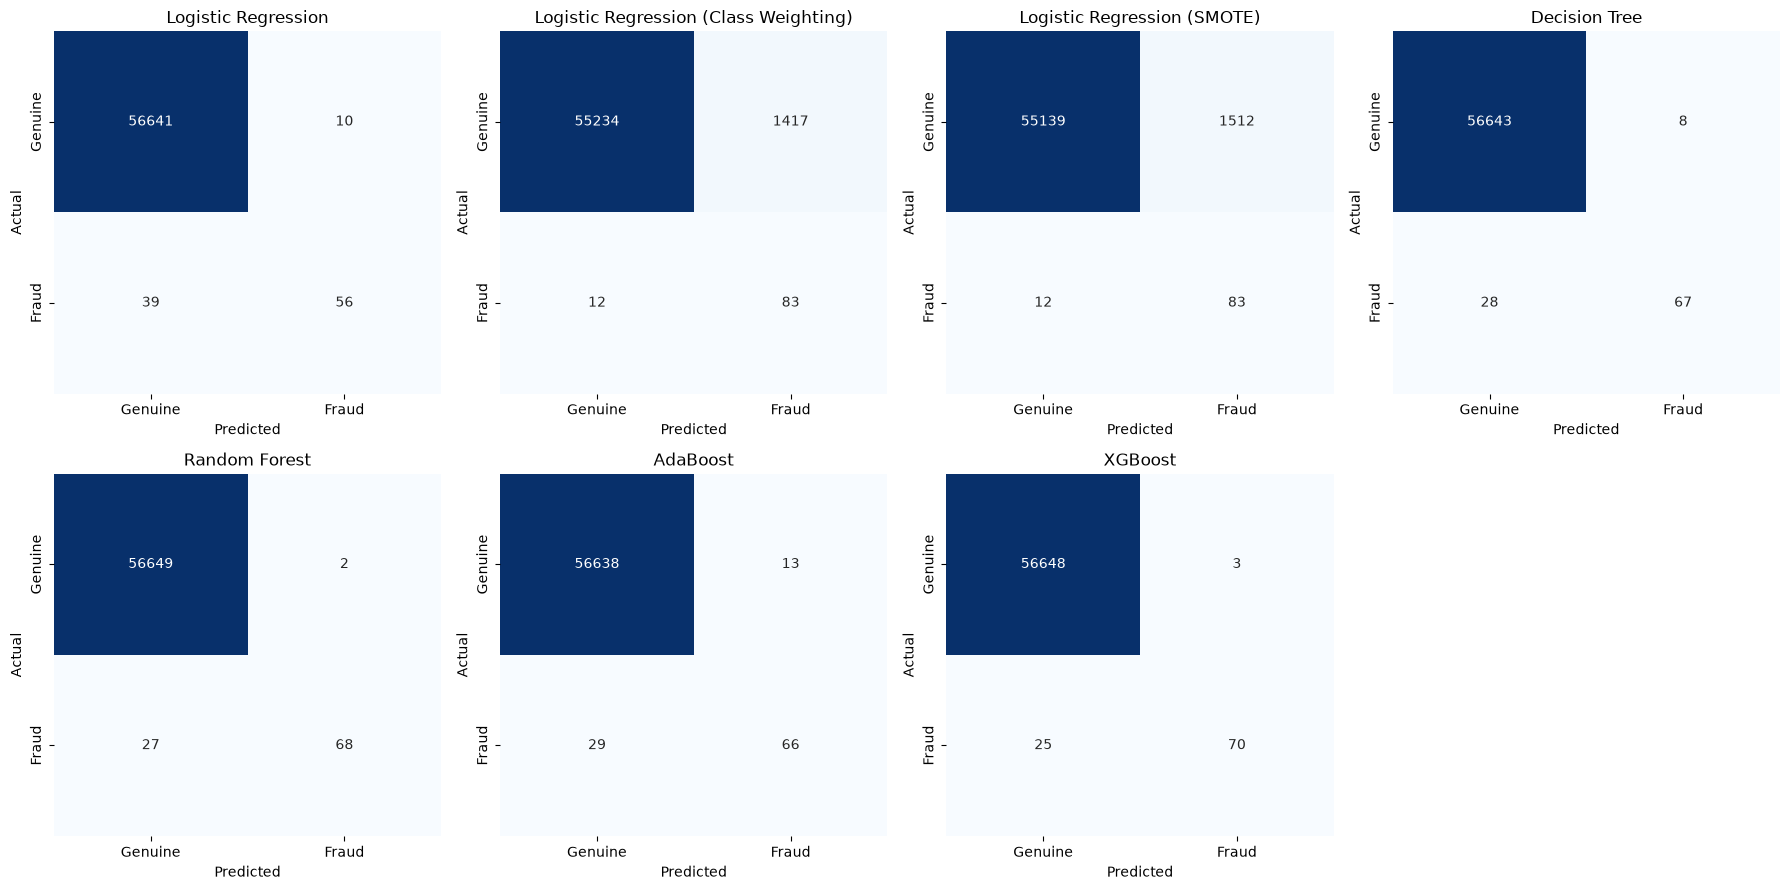

In [35]:
final_models = {
    "Logistic Regression": (lr_baseline, lr_base_pred),
    "Logistic Regression (Class Weighting)": (lr_balanced, lr_bal_pred),
    "Logistic Regression (SMOTE)": (lr_smote, lr_smote_pred),
    "Decision Tree": (decision_tree, dt_pred),
    "Random Forest": (random_forest, rf_pred),
    "AdaBoost": (adaboost, ada_pred),
    "XGBoost": (xgboost_model, xgb_pred)
}

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, (name, (_, predictions)) in zip(axes.flat, final_models.items()):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Genuine", "Fraud"],
        yticklabels=["Genuine", "Fraud"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## 19. Precision-Recall Curves

The precision-recall curve shows how precision and recall change as the classification threshold changes. It is particularly useful for this dataset because fraud is the minority class.

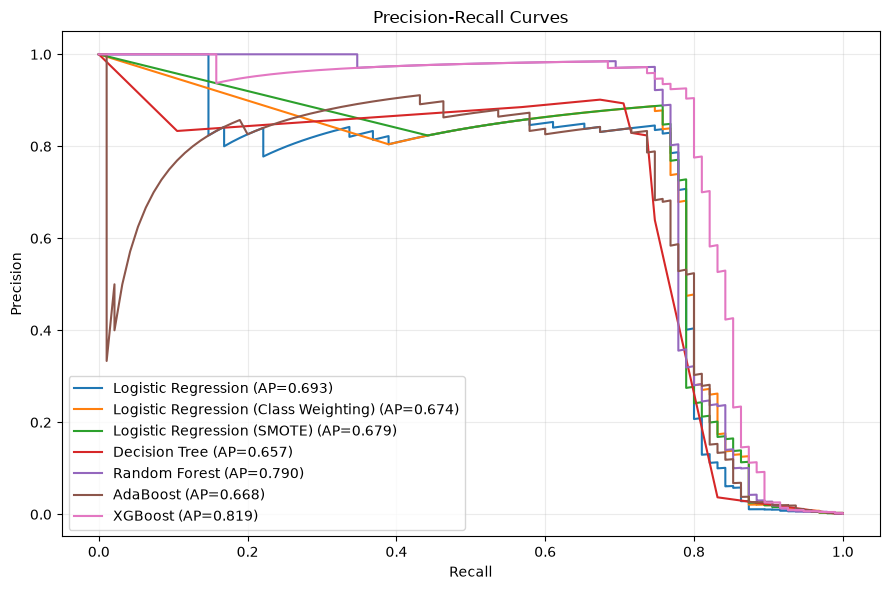

In [36]:
plt.figure(figsize=(9, 6))

for name, (model, _) in final_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    precision_values, recall_values, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    plt.plot(recall_values, precision_values, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 20. Final Observations

The comparison table and plots show how the models behave on the same test data. The best model should not be selected using accuracy alone. Precision, recall, PR-AUC and the number of false positives and false negatives all matter.

In the earlier run of this project, XGBoost and Random Forest were among the strongest models. The final ranking should be based on the results produced when this cleaned notebook is run, since the corrected preprocessing workflow can lead to slightly different scores.

A model with high recall catches more fraudulent transactions, but it may also flag more genuine transactions. A model with high precision makes fewer incorrect fraud alerts, but it may miss more fraud. In a real payment system, the threshold would need to be chosen based on the cost of these two types of errors.

## 21. Limitations and Possible Improvements

- The `V1` to `V28` features are anonymised, so their original meaning cannot be interpreted.
- The dataset is highly imbalanced, and the available examples may not represent every type of real-world fraud.
- The test results are based on one train-test split. Further evaluation on newer or external transaction data would help check how well the model generalises.
- The default classification threshold is used in this notebook. A later improvement could study different thresholds and the resulting precision-recall trade-off.
- This notebook focuses on model development and evaluation. It does not connect to a live banking or payment system.

## Conclusion

This project compares several machine learning approaches for credit card fraud detection. I started by exploring the dataset and understanding the class imbalance, then tested Logistic Regression with different imbalance-handling approaches alongside Decision Tree, Random Forest, AdaBoost and XGBoost.

The results highlight why fraud detection needs more than accuracy as an evaluation metric. Precision, recall, F1-score, PR-AUC and the confusion matrix provide a clearer view of how many fraud cases are detected and how many genuine transactions are incorrectly flagged.

The final model choice should depend on the balance between missed fraud and false alerts, rather than one score alone.